# Sequence-surrogate pipeline: interactive demo

Walks through the whole thing end to end:

1. Roll out `QuenchDetectorEnv` into trajectories (`rollout.py`)
2. Train a GRU sequence surrogate to predict I*/margin from telemetry (`seq_surrogates.py`)
3. Reproduce the analytic runaway surface with it (the notebook-parity check)
4. Watch one live episode: true vs predicted margin as current ramps
5. Wire the surrogate into the env (`env.set_surrogate()`) and compare two controllers:
   - **oracle**: dumps on ground-truth margin ("never let I exceed I*_true")
   - **surrogate**: dumps on the GRU's `margin_pred` (the realistic, deployable controller)

Runs entirely on CPU in a couple of minutes. Re-run any cell after tweaking its parameters.


In [1]:
import sys, pathlib
repo_root = pathlib.Path.cwd()
if not (repo_root / "hts_tape_env").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

import os
for v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(v, "1")  # shared host: uncapped BLAS threads crash on import

import numpy as np
import matplotlib.pyplot as plt

from hts_tape_env.env import QuenchDetectorEnv
from hts_tape_env.rollout import generate_rollout_dataset
from hts_tape_env.seq_surrogates import (
    train_seq_surrogate, load_seq_surrogate, predict_runaway_surface, SequenceSurrogateAdapter,
)
from hts_tape_env.controllers import oracle_controller, surrogate_controller, evaluate, run_episode

%matplotlib inline


## 1. Roll out trajectories from the gym env

This is *not* an i.i.d. sweep of the solver (that's `datagen.py`) -- every row comes from actually stepping `QuenchDetectorEnv`, so the surrogate trains on exactly the ramped, noisy telemetry a policy would see.

In [2]:
N_EPISODES = 400  # bump to 1500 for the full run (~2-3 min); this is enough to see the pipeline work

df = generate_rollout_dataset(N_EPISODES, seed=7, verbose=True)
df.head()


  rolled out 200/400 episodes, 28200 steps so far


Generated 56400 steps over 400 episodes (400/400 reached runaway = 100%).


,episode_id,step,T0_K,I_A,voltage_V,T_surface_K,I_true_A,voltage_true_V,T_surface_true_K,lam,Istar_A,Tstar_K,margin_norm,runaway
0,0,0,48.756683,208.306992,0.000000e+00,48.733948,208.444063,4.739155e-08,48.756683,181.498484,694.813545,69.675629,0.700,0
1,0,1,48.756683,211.422302,1.261024e-07,48.823692,211.918131,6.595876e-08,48.756683,181.498484,694.813545,69.675629,0.695,0
2,0,2,48.756683,215.146103,0.000000e+00,48.781174,215.392199,9.130812e-08,48.756683,181.498484,694.813545,69.675629,0.690,0
3,0,3,48.756683,219.044708,2.311580e-07,48.710159,218.866267,1.257438e-07,48.756683,181.498484,694.813545,69.675629,0.685,0
4,0,4,48.756683,222.325714,8.675990e-07,48.689472,222.340334,1.722958e-07,48.756683,181.498484,694.813545,69.675629,0.680,0


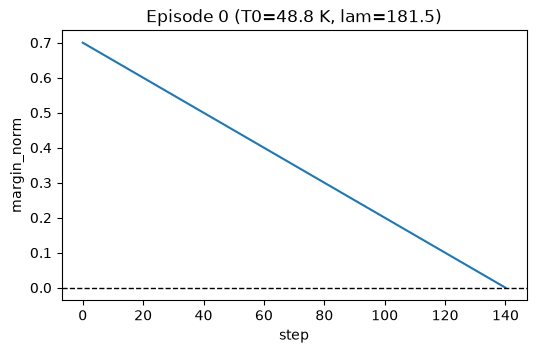

In [3]:
# One trajectory's shape: margin decays as I ramps toward I*
ep0 = df[df.episode_id == 0]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ep0.step, ep0.margin_norm)
ax.axhline(0, ls="--", c="k", lw=1)
ax.set_xlabel("step"); ax.set_ylabel("margin_norm"); ax.set_title(f"Episode 0 (T0={ep0.T0_K.iloc[0]:.1f} K, lam={ep0.lam.iloc[0]:.1f})")
plt.show()


## 2. Train the GRU sequence surrogate

Predicts, from the noiseless telemetry history so far (`seq_data.TRUE_FEATURES` -- see `env.py`'s `info["I_true_A"]` etc.), the running margin at every step and the episode's I* from the trajectory shape alone. It never sees lambda.

In [4]:
# Use a saved checkpoint if you already have one (fast); otherwise train fresh.
CHECKPOINT = repo_root / "models" / "seq_gru.pt"

if CHECKPOINT.exists():
    result = load_seq_surrogate(CHECKPOINT)
    print(f"Loaded {CHECKPOINT} -- metrics: {result.metrics}")
else:
    result = train_seq_surrogate(df, arch="gru", epochs=40, seed=7)
    result.save(CHECKPOINT)
    print(f"Trained fresh, saved to {CHECKPOINT} -- metrics: {result.metrics}")


Loaded /home/mairakhan/fanc/magnets_rl/quench_detector/models/seq_gru.pt -- metrics: {'best_val_loss': 0.0017630904214456678, 'istar_mae_A': 6.988414764404297, 'istar_median_rel_err': 0.007666097022593021}


## 3. Reproduce the analytic runaway surface

The notebook-parity check: for a grid of exact (T0, lambda), roll out one full episode and ask the surrogate for I* from the whole trajectory -- compare to the analytic solver. Lambda is never an input.

surface median rel err: 0.72%   95th pct: 2.98%


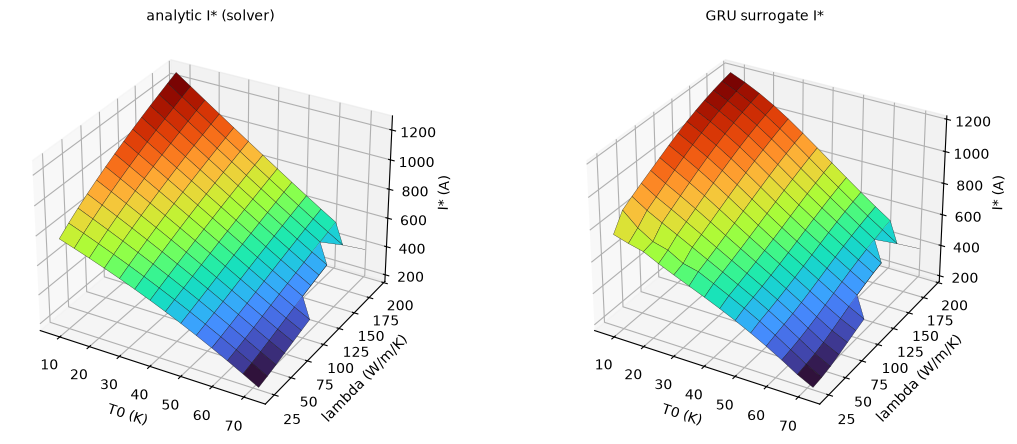

In [5]:
T0_grid = np.linspace(8.0, 72.0, 14)
lam_grid = np.linspace(24.0, 190.0, 14)
Istar_analytic, Istar_pred = predict_runaway_surface(result, T0_grid, lam_grid, seed=12345)

rel_err = np.abs(Istar_pred - Istar_analytic) / np.maximum(Istar_analytic, 1e-6)
print(f"surface median rel err: {np.nanmedian(rel_err):.2%}   95th pct: {np.nanpercentile(rel_err, 95):.2%}")

TT, LL = np.meshgrid(T0_grid, lam_grid)
fig = plt.figure(figsize=(12, 4.5))
for i, (Z, title) in enumerate([(Istar_analytic, "analytic I* (solver)"), (Istar_pred, "GRU surrogate I*")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot_surface(TT, LL, Z, cmap="turbo", edgecolor="k", linewidth=0.2)
    ax.set_xlabel("T0 (K)"); ax.set_ylabel("lambda (W/m/K)"); ax.set_zlabel("I* (A)")
    ax.set_title(title, fontsize=10)
fig.tight_layout()
plt.show()


## 4. Watch one live episode with the surrogate attached

`env.set_surrogate()` primes `info["margin_pred"]` / `info["I_star_pred"]` every step (GRU hidden state carried across steps -- true streaming inference). Watch the estimate sharpen as more of the ramp is seen.

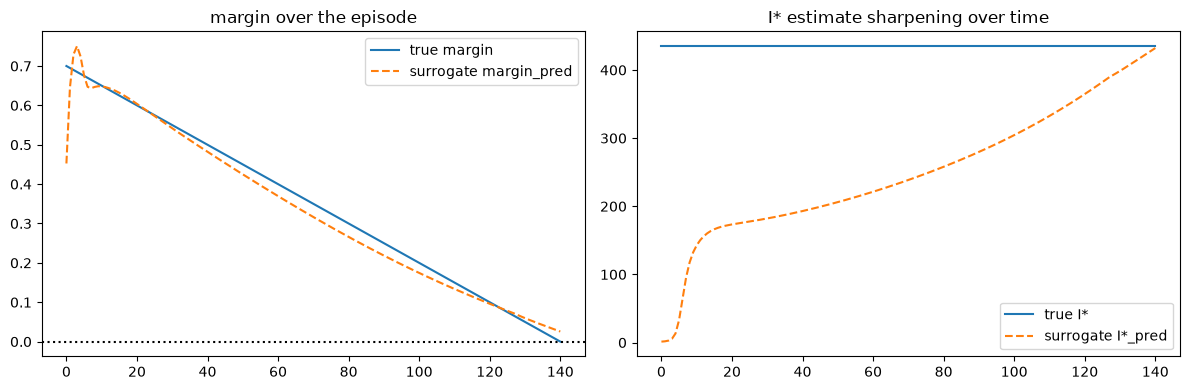

In [6]:
env = QuenchDetectorEnv()
env.set_surrogate(SequenceSurrogateAdapter(result))

obs, info = env.reset(seed=42)
trace = []
while True:
    trace.append(dict(margin=info["margin"], margin_pred=info["margin_pred"],
                       Istar=info["I_star"], Istar_pred=info["I_star_pred"]))
    obs, reward, terminated, truncated, info = env.step(0)  # always continue
    if terminated or truncated:
        trace.append(dict(margin=info["margin"], margin_pred=info["margin_pred"],
                           Istar=info["I_star"], Istar_pred=info["I_star_pred"]))
        break

import pandas as pd
trace = pd.DataFrame(trace)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(trace.margin, label="true margin")
axes[0].plot(trace.margin_pred, "--", label="surrogate margin_pred")
axes[0].axhline(0, ls=":", c="k"); axes[0].legend(); axes[0].set_title("margin over the episode")
axes[1].plot(trace.Istar, label="true I*")
axes[1].plot(trace.Istar_pred, "--", label="surrogate I*_pred")
axes[1].legend(); axes[1].set_title("I* estimate sharpening over time")
plt.tight_layout(); plt.show()


## 5. Two controllers

We haven't trained an RL policy yet -- these are the two simplest baselines, both just
"bang-bang" (binary on/off) on the `Discrete(2)` action space, pointed at different signals:

- **`oracle_controller()`** -- dumps on the ground-truth `margin` (from `I*_true`). This is
  "never let I go above I*_true" with perfect knowledge -- the best any controller sharing
  this action/reward structure can do.
- **`surrogate_controller()`** -- dumps on the GRU's `margin_pred`. This is the realistic,
  deployable controller: it never observes `I*_true`, only the live telemetry.


In [7]:
N_EVAL_EPISODES = 200

env_oracle = QuenchDetectorEnv()
oracle_metrics = evaluate(env_oracle, oracle_controller(env_oracle.dump_threshold),
                           n_episodes=N_EVAL_EPISODES, seed0=999)

env_surr = QuenchDetectorEnv()
env_surr.set_surrogate(SequenceSurrogateAdapter(result))
surrogate_metrics = evaluate(env_surr, surrogate_controller(env_surr.dump_threshold),
                              n_episodes=N_EVAL_EPISODES, seed0=999)

import pandas as pd
pd.DataFrame([oracle_metrics, surrogate_metrics]).set_index("controller")


,mean_reward,hit_rate,miss_rate,false_alarm_rate,mean_final_margin
controller,,,,,
oracle (true I*),11.00,1.000,0.000,0.00,0.045000
surrogate (margin_pred),0.83,0.605,0.145,0.25,0.036125


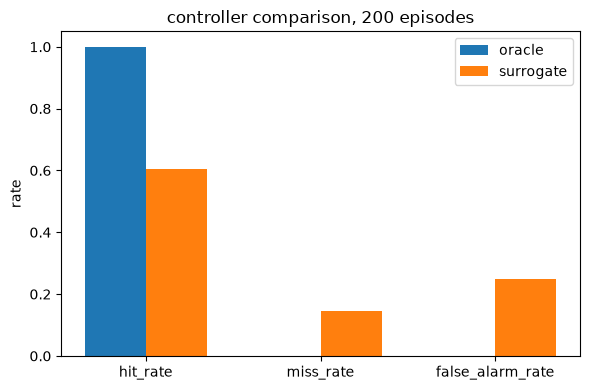

In [8]:
metrics_to_plot = ["hit_rate", "miss_rate", "false_alarm_rate"]
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(metrics_to_plot))
width = 0.35
ax.bar(x - width/2, [oracle_metrics[m] for m in metrics_to_plot], width, label="oracle")
ax.bar(x + width/2, [surrogate_metrics[m] for m in metrics_to_plot], width, label="surrogate")
ax.set_xticks(x); ax.set_xticklabels(metrics_to_plot)
ax.set_ylabel("rate"); ax.legend(); ax.set_title(f"controller comparison, {N_EVAL_EPISODES} episodes")
plt.tight_layout(); plt.show()


## What this shows

The oracle controller (perfect knowledge of I*_true) always wins -- that's the reward ceiling.
The surrogate controller's gap to it is the actual, honest measure of how good the trained
sequence model is *as a decision-maker*, not just as a regressor: aggregate I* error can look
excellent (sub-1%) while the controller still misses/false-alarms near the boundary, because
that error is comparable in size to the dump-threshold band itself. See PROGRESS.md / the
conversation history for what's next (boundary-weighted training, an actual RL-trained policy,
multi-conductor generalization).
